In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

In [5]:
df = pd.read_csv("most_used_beauty_cosmetics_products_extended.csv")

print(df.head())
print(df.shape)
print(df.info())

       Product_Name              Brand        Category Usage_Frequency  \
0   Ultra Face Mask     Drunk Elephant           Blush          Weekly   
1    Ultra Lipstick      Laura Mercier  Makeup Remover      Occasional   
2       Ultra Serum     Natasha Denona     Highlighter           Daily   
3      Divine Serum        Ilia Beauty       Face Mask      Occasional   
4  Super Foundation  Charlotte Tilbury     Highlighter      Occasional   

   Price_USD  Rating  Number_of_Reviews Product_Size  Skin_Type Gender_Target  \
0      67.85     1.4                686         30ml  Sensitive        Female   
1     116.43     4.2               5483        250ml        Dry        Unisex   
2      90.84     1.6               5039        100ml  Sensitive          Male   
3      55.17     3.2               6202        250ml     Normal          Male   
4     140.56     1.7                297        100ml       Oily        Female   

  Packaging_Type Main_Ingredient  Cruelty_Free Country_of_Origin  
0

In [6]:
print(df["Rating"].describe())
print(df["Rating"].isnull().sum())

count    15000.000000
mean         3.002327
std          1.168029
min          1.000000
25%          2.000000
50%          3.000000
75%          4.000000
max          5.000000
Name: Rating, dtype: float64
0


In [7]:
features = [
    "Price_USD",
    "Number_of_Reviews",
    "Brand",
    "Category",
    "Usage_Frequency",
    "Product_Size",
    "Skin_Type",
    "Gender_Target",
    "Packaging_Type",
    "Main_Ingredient",
    "Cruelty_Free",
    "Country_of_Origin"
]

features = [col for col in features if col in df.columns]

X = df[features].copy()
y = df["Rating"].copy()

print("Input features:")
print(X.head())

print("Target variable:")
print(y.head())

Input features:
   Price_USD  Number_of_Reviews              Brand        Category  \
0      67.85                686     Drunk Elephant           Blush   
1     116.43               5483      Laura Mercier  Makeup Remover   
2      90.84               5039     Natasha Denona     Highlighter   
3      55.17               6202        Ilia Beauty       Face Mask   
4     140.56                297  Charlotte Tilbury     Highlighter   

  Usage_Frequency Product_Size  Skin_Type Gender_Target Packaging_Type  \
0          Weekly         30ml  Sensitive        Female           Tube   
1      Occasional        250ml        Dry        Unisex         Bottle   
2           Daily        100ml  Sensitive          Male        Compact   
3      Occasional        250ml     Normal          Male           Tube   
4      Occasional        100ml       Oily        Female        Compact   

  Main_Ingredient  Cruelty_Free Country_of_Origin  
0         Retinol         False         Australia  
1     Shea But

In [8]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

Numerical features: ['Price_USD', 'Number_of_Reviews']
Categorical features: ['Brand', 'Category', 'Usage_Frequency', 'Product_Size', 'Skin_Type', 'Gender_Target', 'Packaging_Type', 'Main_Ingredient', 'Cruelty_Free', 'Country_of_Origin']


In [9]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (12000, 12)
Testing data: (3000, 12)


In [12]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression trained successfully!")
print("First 10 predictions:")
print(linear_predictions[:10])

Linear Regression trained successfully!
First 10 predictions:
[3.13825393 3.05456513 3.03707309 3.08576807 2.8406949  3.1310639
 3.11966846 3.00936311 3.02314037 3.06245027]


In [13]:
decision_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DecisionTreeRegressor(
        max_depth=5,
        random_state=42
    ))
])

decision_model.fit(X_train, y_train)

decision_predictions = decision_model.predict(X_test)

print("Decision Tree trained successfully!")
print("First 10 predictions:")
print(decision_predictions[:10])

Decision Tree trained successfully!
First 10 predictions:
[2.97079114 2.97079114 2.97079114 2.97079114 2.97079114 2.97079114
 2.97079114 3.11219262 2.97079114 2.97079114]


In [14]:
random_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ))
])

random_model.fit(X_train, y_train)

random_predictions = random_model.predict(X_test)

print("Random Forest trained successfully!")
print("First 10 predictions:")
print(random_predictions[:10])

Random Forest trained successfully!
First 10 predictions:
[3.01212695 2.98373735 3.01841161 3.06177877 2.97472739 3.01292551
 2.98954861 3.15735799 3.00302172 3.01365543]


In [15]:
models = {
    "Linear Regression": linear_predictions,
    "Decision Tree": decision_predictions,
    "Random Forest": random_predictions
}

results = []

for name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    mse = mean_squared_error(y_test, predictions)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

print(results_df)

               Model       MAE       MSE      RMSE  R2 Score
0  Linear Regression  1.025660  1.386350  1.177434 -0.009610
1      Decision Tree  1.027241  1.397310  1.182079 -0.017591
2      Random Forest  1.024351  1.383158  1.176077 -0.007285


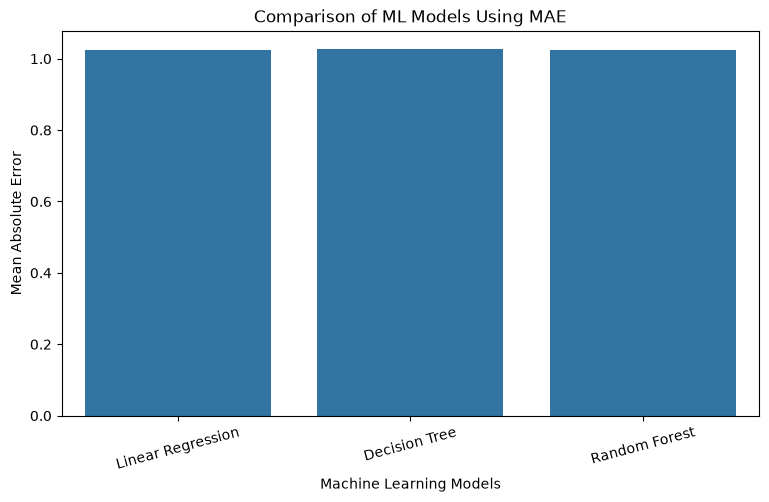

In [16]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="MAE"
)

plt.title("Comparison of ML Models Using MAE")
plt.xlabel("Machine Learning Models")
plt.ylabel("Mean Absolute Error")
plt.xticks(rotation=15)
plt.show()

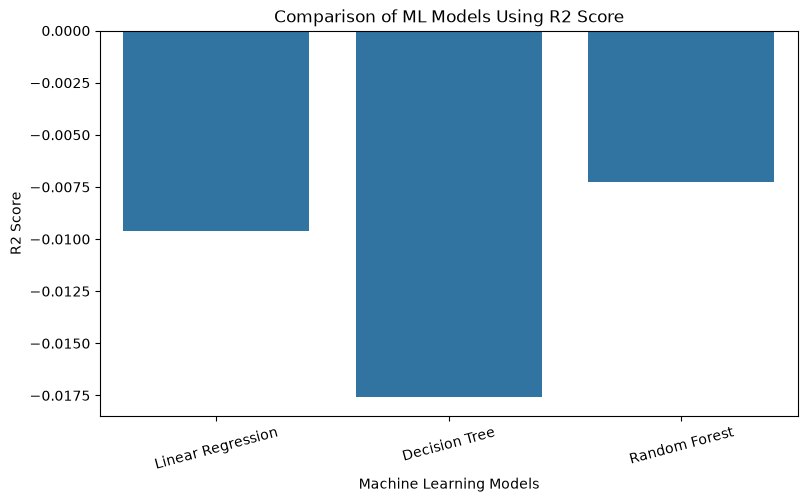

In [17]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2 Score"
)

plt.title("Comparison of ML Models Using R2 Score")
plt.xlabel("Machine Learning Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=15)
plt.show()

In [18]:
comparison = pd.DataFrame({
    "Actual Rating": y_test.values,
    "Predicted Rating": random_predictions
})

print(comparison.head(10))

   Actual Rating  Predicted Rating
0            4.1          3.012127
1            1.8          2.983737
2            3.1          3.018412
3            4.8          3.061779
4            4.2          2.974727
5            2.6          3.012926
6            2.0          2.989549
7            1.7          3.157358
8            4.8          3.003022
9            2.3          3.013655


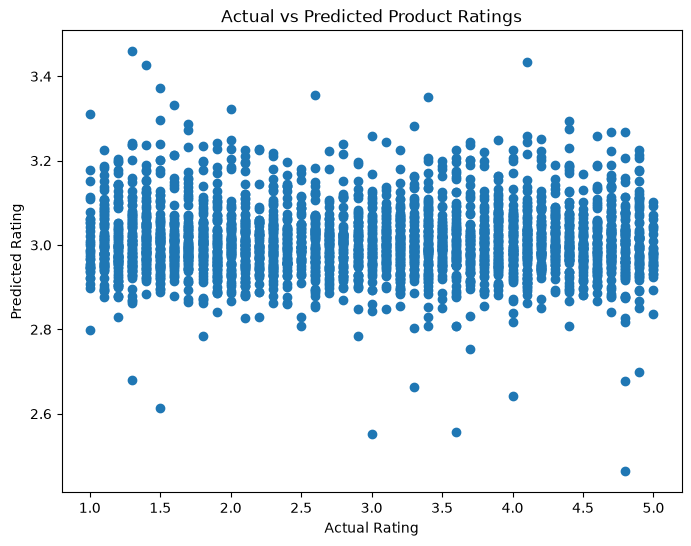

In [19]:
plt.figure(figsize=(8, 6))

plt.scatter(
    comparison["Actual Rating"],
    comparison["Predicted Rating"]
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Product Ratings")

plt.show()

In [20]:
cv_scores = cross_val_score(
    random_model,
    X_train,
    y_train,
    cv=5,
    scoring="neg_mean_absolute_error"
)

cv_mae = -cv_scores

print("Cross Validation MAE scores:", cv_mae)
print("Average Cross Validation MAE:", cv_mae.mean())

Cross Validation MAE scores: [1.02190921 1.00678091 0.99380326 1.03664341 1.00457331]
Average Cross Validation MAE: 1.0127420212028824


In [21]:
train_predictions = random_model.predict(X_train)
test_predictions = random_model.predict(X_test)

print(
    "Training MAE:",
    mean_absolute_error(y_train, train_predictions)
)

print(
    "Testing MAE:",
    mean_absolute_error(y_test, test_predictions)
)

Training MAE: 0.9441728859370545
Testing MAE: 1.024351002696774


In [22]:
rf = random_model.named_steps["model"]

feature_names = random_model.named_steps[
    "preprocessor"
].get_feature_names_out()

importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance.head(10))

                             Feature  Importance
0                     num__Price_USD    0.176661
1             num__Number_of_Reviews    0.172008
78             cat__Skin_Type_Normal    0.013266
82           cat__Gender_Target_Male    0.011502
68   cat__Usage_Frequency_Occasional    0.011055
72           cat__Product_Size_200ml    0.010983
83         cat__Gender_Target_Unisex    0.010971
99  cat__Country_of_Origin_Australia    0.010915
86           cat__Packaging_Type_Jar    0.010885
80          cat__Skin_Type_Sensitive    0.010789


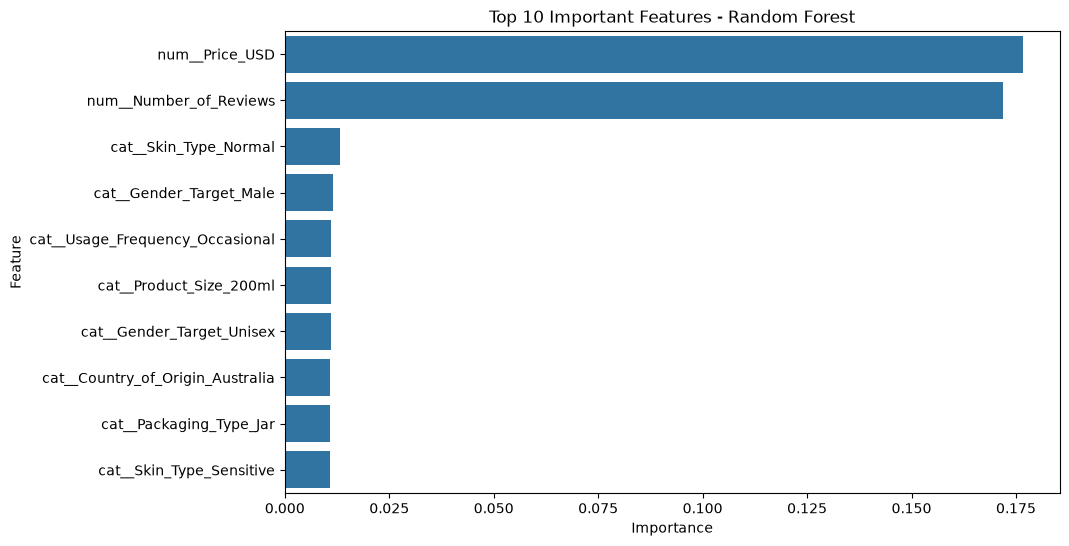

In [23]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Important Features - Random Forest")
plt.show()

In [24]:
results_df.to_csv(
    "week5_model_comparison.csv",
    index=False
)

print("Model comparison saved successfully!")

Model comparison saved successfully!


In [25]:
importance.to_csv(
    "week5_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")

Feature importance saved successfully!
